# 제10교시. Thinking / Non-thinking의 관찰 가능한 출력


## 이번 교시의 목표

- 같은 체크포인트에서 template 옵션이 실제 입력을 어떻게 바꾸는지 확인합니다.
- 생성 토큰·종료 경계·최종 숫자를 읽어 미완료와 오답을 구분합니다.
- 네 생성 기록이 보여 주는 사실과 일반 추론 능력에 관한 주장을 구분합니다.


## 이번 교시 핵심 용어

- **추론(reasoning)**: 문제를 풀어 답을 도출하는 능력·과정을 가리키며, 여기서는 보이는 출력만 관찰합니다.
- **채팅 템플릿(chat template)**: 역할·경계·생성 시작 표식을 포함한 모델 전용 입력 형식입니다.
- **생성 토큰 상한(generation token limit)**: 입력을 제외하고 새로 생성할 토큰 수의 최대치입니다.
- **시퀀스 종료(end of sequence, EOS)**: 시퀀스가 끝났음을 알리는 토큰이며 길이 상한에 의한 중단과 구분합니다.



## 실습 준비

1교시에서 준비한 Windows 프로젝트의 Python 커널을 선택하고 CUDA 환경을 확인합니다. 앞 교시의 모델이 남아 있으면 해당 커널을 종료하고 새 커널에서 시작합니다. 아래 환경 검사와 실제 출력에서 버전·장치를 확인한 뒤 순서대로 실행합니다.

가중치는 지정된 공식 체크포인트와 revision을 사용합니다. 결과 파일은 이 노트북의 `OUT`에 지정된 폴더에 저장하며, 이미지 실습은 코드로 만든 공개 도형만 사용합니다.

**커널·필수 도구:** 1교시에서 만든 프로젝트의 Python 3.12 커널을 선택합니다. 수업 환경은 PyTorch 2.9.1(CUDA 12.6 빌드), Transformers 5.23.0이며 Pillow·NumPy·Matplotlib·huggingface_hub를 사용합니다. 패키지가 없거나 버전이 다르면 이 노트북에서 임의로 업그레이드하지 말고 1교시에서 준비한 환경을 복구한 뒤 커널을 재시작합니다.

**파일·다운로드:** 실행 셀에서 Qwen3-0.6B의 고정 revision을 읽습니다. 첫 실행에는 공식 모델 저장소 접속과 가중치 다운로드가 필요하며 이후 같은 다운로드 캐시를 재사용합니다. API 키·유료 추론 API·개인 데이터는 필요하지 않습니다. 연결 오류가 나면 실패 셀을 확인하고 네트워크 복구 뒤 그 셀부터 다시 실행합니다. 인증 토큰을 노트북에 적지 않습니다.

**실행·확인 순서:** 위에서부터 개념과 그림, 코드 설명을 본 뒤 코드 셀을 한 번씩 실행하고 바로 아래 실제 출력·출력 설명을 확인합니다. `assert` 오류가 나오면 뒤 셀로 넘어가지 않습니다. CUDA 사용 불가면 장치·커널을 먼저 확인하고, 메모리 부족이면 결과를 보관한 뒤 이전 모델이 남은 커널을 종료하고 새 커널에서 다시 시작합니다. 이미지나 텍스트의 오답은 환경 오류와 구분합니다.

**결과 보관:** `OUT`과 마지막 저장 경로 출력에서 JSON·그림 폴더를 확인합니다. 실행 횟수와 출력이 남은 `.ipynb`도 저장합니다. 다시 실행해 기록이 중복되면 새 커널에서 처음부터 진행합니다.

**오늘의 질문:** 같은 체크포인트에 다른 chat template 설정을 주었을 때, 우리가 실제로 확인할 수 있는 것은 무엇인가요?

공식 **Qwen3-0.6B**의 실제 가중치 하나를 사용합니다. 모형을 축소하거나 임의 출력 예시를 만들지 않습니다.

**Qwen3-0.6B**는 Qwen 팀이 [2025년 4월 29일](https://qwenlm.github.io/blog/qwen3/)에 공개한 Qwen3 계열의 소형 모델입니다. 8교시에서 본 Qwen3-4B와 같은 날 공개됐지만, 이번 실습에서 실행하는 것은 0.6B입니다.

다른 모델을 커널에서 내리고 시작하세요. 첫 다운로드는 실제 model.safetensors 약**1.50GB**와 tokenizer 파일 약16MB가 추가됩니다. 같은 체크포인트 캐시는 재사용합니다. 무인 전체 재실행보다 각 셀을 읽고 실행하세요. 새 패키지를 설치하거나 별도 서버를 띄우지 않습니다.


## 1. 무엇을 바꾸고 무엇을 고정할까요?
`enable_thinking`은 공식 tokenizer의 chat template 옵션입니다. 구조나 가중치를 갈아끼우는 실험이 아닙니다. 각 모드의 입력 template 끝부분을 직접 확인합니다.

[고정 revision의 공식 모델 카드](https://huggingface.co/Qwen/Qwen3-0.6B/blob/c1899de289a04d12100db370d81485cdf75e47ca/README.md)는 thinking에 sampling을 권장하며 greedy를 피하라고 안내합니다. 여기서는 비교에서 변수를 줄이려고 양쪽 모두 temperature0.6/top_p0.95/top_k20/min_p0을 사용합니다. 이는 **비교 실험 설정**이며 공식 non-thinking 권장값(0.7/0.8)과 다릅니다. 같은 seed여도 서로 다른 길이·template가 동일 난수 경로 또는 같은 결과를 보장하지 않습니다.

두 문제만으로 추론 성능을 평가하지 않습니다. 시간은 전체 generate 구간의 관찰값이고 벤치마크가 아닙니다. 최대384토큰에서 끊긴 응답은 미완료로 표시하고 끝나지 않은 초안을 최종 답으로 간주하지 않습니다.

이 실습에서 바꾸는 것은 **같은 모델에게 대화를 제시하는 형식**입니다. `enable_thinking`은 새 뇌나 층을 붙이는 스위치가 아니라, 체크포인트가 학습한 대화 형식 중 어느 생성 모드를 사용할지 정하는 옵션입니다. 따라서 두 설정의 차이를 구조가 다른 모델의 성능 차이라고 설명하면 안 됩니다.

관찰할 수 있는 것은 출력된 토큰과 문장입니다. 풀이가 길어도 틀릴 수 있고 짧아도 맞을 수 있습니다. 먼저 “답변이 끝났는가?”, 다음으로 “최종 숫자가 맞는가?”를 묻습니다. 예를 들어 길이 한도 때문에 최종 답 전에 멈춘 경우는, 완성된 답으로 틀린 숫자를 제시한 경우와 다릅니다.

### 개념 먼저

추론 모드는 모델 안에 새로운 블록을 끼우는 스위치가 아닙니다. 같은 책을 읽은 사람에게 ‘답만 말해 주세요’와 ‘먼저 풀어 보고 답해 주세요’라는 서로 다른 응답 형식을 요청하는 상황에 가깝습니다. 이 비유는 입력 형식 차이를 이해하기 위한 것이며, 모델이 사람처럼 생각한다는 뜻은 아닙니다. 실제로 바뀌는 것은 채팅 템플릿의 제어 표식이고 모델 구조와 가중치는 같습니다.

따라서 확인할 질문도 ‘추론 기능이 켜지면 무조건 정답인가’가 아니라 ‘입력이 어떻게 달라지고, 무엇을 생성하며, 상한 안에 최종 답까지 도달하는가’입니다. 아래 실험은 문제·샘플링 조건·토큰 예산을 기록하고 두 모드의 관찰값을 나란히 남깁니다. 보이는 초안은 관찰 가능한 생성 텍스트이지 내부 계산 전체를 직접 읽은 기록은 아닙니다.


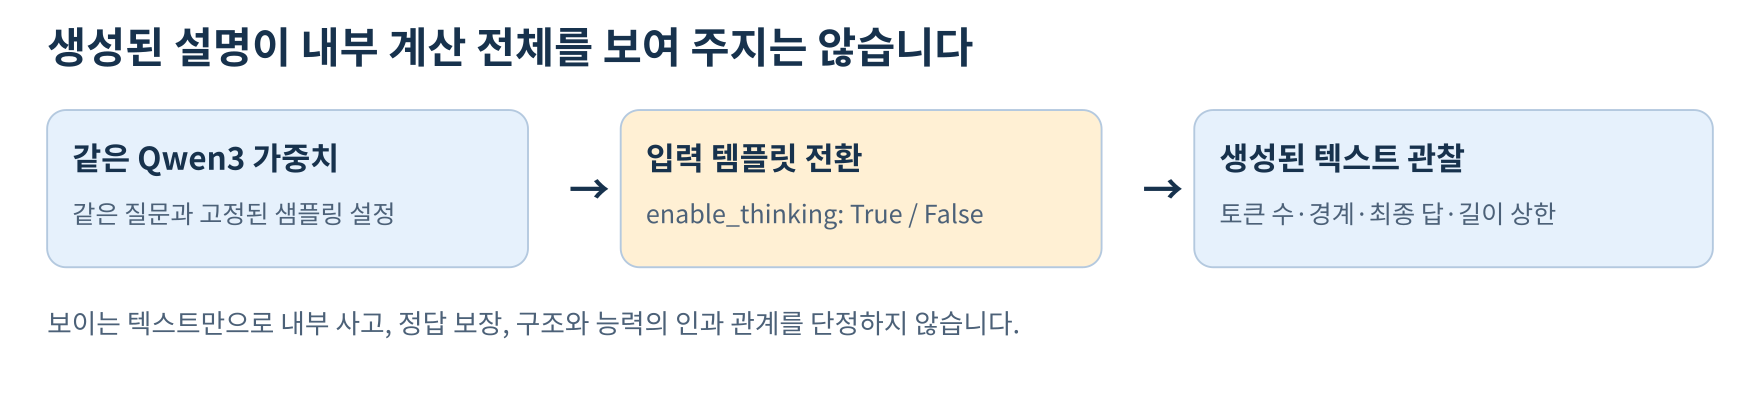

### 코드 설명: 관찰 가능한 출력 비교를 준비하기

Qwen3-0.6B의 같은 가중치로 thinking 모드와 non-thinking 모드를 비교합니다. 여기서 thinking은 별도의 모델을 훈련하거나 새로운 층을 추가한다는 뜻이 아니라, 해당 모델의 대화 템플릿에서 사용하는 생성 모드 설정입니다. 출력되는 초안 텍스트는 관찰 가능한 생성물이며, 모델 내부의 모든 계산이나 실제 사고 과정을 그대로 보여 주는 기록이라고 해석하지 않습니다.

`QUESTIONS`는 정답을 손으로 확인할 수 있는 두 문제이고, `MAX_NEW_TOKENS=384`는 입력을 제외한 새 토큰의 상한입니다. `dtype`는 수치 저장·연산 정밀도, `temperature`, `top_p`, `top_k`는 다음 토큰을 뽑는 샘플링 조건입니다. 출력의 모델·revision·정밀도·샘플링 설정을 확인하세요. `[PASS] ... 체크포인트 로드`는 가중치를 읽고 기본 검사를 마쳤다는 뜻이며, 추론 능력이나 정답률을 검증한 결과가 아닙니다.


In [1]:
import os, sys, json, time, gc, platform, re
from pathlib import Path
from datetime import datetime, timezone
import torch, transformers
from transformers import AutoTokenizer,AutoModelForCausalLM,set_seed
assert platform.system()=="Windows", "Windows11 프로젝트 커널을 사용하세요."
assert torch.cuda.is_available(), "1교시 CUDA 환경을 확인하세요."
DEVICE=torch.device("cuda:0")
MODEL_ID="Qwen/Qwen3-0.6B"
REVISION="c1899de289a04d12100db370d81485cdf75e47ca"
# 입력 길이가 아니라 새로 생성할 토큰 수의 상한입니다.
MAX_NEW_TOKENS=384
CACHE=os.environ.get("LESSON10_QWEN3_CACHE") or None
# 동일 revision을 토크나이저와 모델에 함께 적용하여 입력 규약과 가중치 버전을 맞춥니다.
args=dict(revision=REVISION,cache_dir=CACHE)
# 토크나이저는 문자열 변환 규칙, 아래 모델은 다음 토큰 예측 가중치를 읽습니다.
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,**args)
# safetensors는 파일 형식, float16은 연산 자료형, eager는 어텐션 구현 선택입니다.
model=AutoModelForCausalLM.from_pretrained(MODEL_ID,**args,use_safetensors=True,
    dtype=torch.float16,attn_implementation="eager").to(DEVICE).eval()
# 모든 파라미터의 장치를 검사하며 정답 여부를 검사하는 것은 아닙니다.
assert all(p.device.type=="cuda" for p in model.parameters())
assert model.config.model_type=="qwen3"
META={"created_utc":datetime.now(timezone.utc).isoformat(),"pc":platform.node(),"gpu":torch.cuda.get_device_name(0),
      "python":sys.version,"executable":sys.executable,"torch":torch.__version__,"transformers":transformers.__version__,
      "model":MODEL_ID,"revision":REVISION,"dtype":"float16","attention":"eager",
      "sampling":{"temperature":0.6,"top_p":0.95,"top_k":20,"min_p":0.0},"max_new_tokens":MAX_NEW_TOKENS}
OUT=Path("results")/"lesson10"/datetime.now().strftime("%Y%m%d-%H%M%S-%f")
# 동일한 폴더가 있으면 중단하여 서로 다른 실행 결과가 섞이지 않게 합니다.
OUT.mkdir(parents=True,exist_ok=False)
# 정답이 명확한 두 문제로 모드별 출력을 관찰합니다. 일반 추론 능력 벤치마크는 아닙니다.
QUESTIONS=[
    {"id":"pencils","text":"A box has 12 pencils. Mina removes 3 and adds 5. How many pencils are now in the box? End your final answer with FINAL: followed by the integer.","answer":"14"},
    {"id":"decimal","text":"Which decimal number is larger, 9.11 or 9.9? End your final answer with FINAL: followed by the larger number.","answer":"9.9"},
]
print(json.dumps(META,ensure_ascii=False,indent=2))
print("[PASS] 실제 공식 Qwen3 체크포인트 로드")

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 22:10:57.918000 36604 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.



Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]


Loading weights:  17%|█▋        | 53/311 [00:00<00:00, 511.96it/s]


Loading weights:  34%|███▍      | 105/311 [00:00<00:00, 459.30it/s]


Loading weights:  49%|████▉     | 152/311 [00:00<00:00, 406.85it/s]


Loading weights:  62%|██████▏   | 194/311 [00:00<00:00, 400.27it/s]


Loading weights:  76%|███████▌  | 235/311 [00:00<00:00, 382.37it/s]


Loading weights:  88%|████████▊ | 274/311 [00:00<00:00, 381.18it/s]


Loading weights: 100%|██████████| 311/311 [00:00<00:00, 404.91it/s]

{
  "created_utc": "2026-11-17T13:10:59.974223+00:00",
  "pc": "검증 PC",
  "gpu": "NVIDIA GeForce RTX 4090",
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "executable": "%USERPROFILE%\\AI-Engineering\\python31210-signed-qa-20261117\\.venv\\Scripts\\python.exe",
  "torch": "2.9.1+cu126",
  "transformers": "5.23.0",
  "model": "Qwen/Qwen3-0.6B",
  "revision": "c1899de289a04d12100db370d81485cdf75e47ca",
  "dtype": "float16",
  "attention": "eager",
  "sampling": {
    "temperature": 0.6,
    "top_p": 0.95,
    "top_k": 20,
    "min_p": 0.0
  },
  "max_new_tokens": 384
}
[PASS] 실제 공식 Qwen3 체크포인트 로드


### 출력 설명

저장된 출력은 Python 3.12.10·PyTorch 2.9.1+cu126·Transformers 5.23.0, RTX 4090에서 실행한 기록입니다. 이 장치에서 통과한 기록을 다른 GPU의 속도나 메모리 충분함에 대한 보장으로 읽지 않습니다. 

Qwen3-0.6B가 FP16·eager attention으로 로드됐고 샘플링 조건과 생성 상한 384가 기록됐습니다. 로드 PASS는 가중치·모델 종류 준비의 성공이며 아직 두 문제의 정답이나 완료 여부를 평가하지 않았습니다.

IProgress 경고는 진행 막대용 위젯을 찾지 못했다는 안내입니다. 이 기록은 이후 PASS까지 진행했으므로 가중치나 CUDA 계산 실패의 증거가 아닙니다.

프로세스 출력 리다이렉션 미지원 안내가 함께 기록됐지만 모델 로드·검사는 완료됐습니다. 이 메시지를 모델의 추론 실패나 수업에 필요한 분산 실행 설정으로 해석하지 않습니다.


## 2. 두 template를 먼저 비교
같은 user 질문을 넣습니다. non-thinking template에는 빈 think 구간이 **입력에** 들어갈 수 있습니다. 이것을 모델이 새로 생성한 reasoning 텍스트로 세지 않습니다. 출력 토큰은 입력 길이 뒤에서 잘라 따로 보관합니다.

채팅 템플릿(chat template)은 사용자의 질문에 역할·경계·응답 시작 표식을 붙이는 형식입니다. 사람이 보는 질문 한 문장이 같아도 모델이 실제로 받는 문자열은 달라질 수 있습니다. 입력에 이미 적힌 빈 think 표식을 모델이 새로 생성한 초안으로 세지 않도록, **입력 토큰 경계 뒤의 생성분만** 분리해 읽습니다.

### 개념 먼저

입력에 이미 있는 글자와 모델이 새로 만든 글자를 먼저 나눠야 합니다. 예를 들어 답안지에 미리 인쇄된 ‘풀이:’를 학생이 작성한 풀이의 첫 줄로 세지 않는 것과 같습니다. 템플릿이 입력 끝에 빈 think 구간을 넣었다면 그 표식은 생성 초안이 아닙니다. 반대로 입력 끝의 열린 표식 뒤를 모델이 이어 쓴 부분은 생성 기록입니다.

아래에서는 문자열을 먼저 출력하고 입력 토큰 수를 확인합니다. 다음 생성 셀은 반환된 전체 토큰열에서 입력 길이만큼 잘라 새 부분만 분석합니다. 이 구분을 하지 않으면 초안 길이나 최종 답 경계를 잘못 셀 수 있습니다. 그림의 경계는 개념 설명이며, 저장된 실제 표식과 길이는 바로 아래 출력으로 확인합니다.


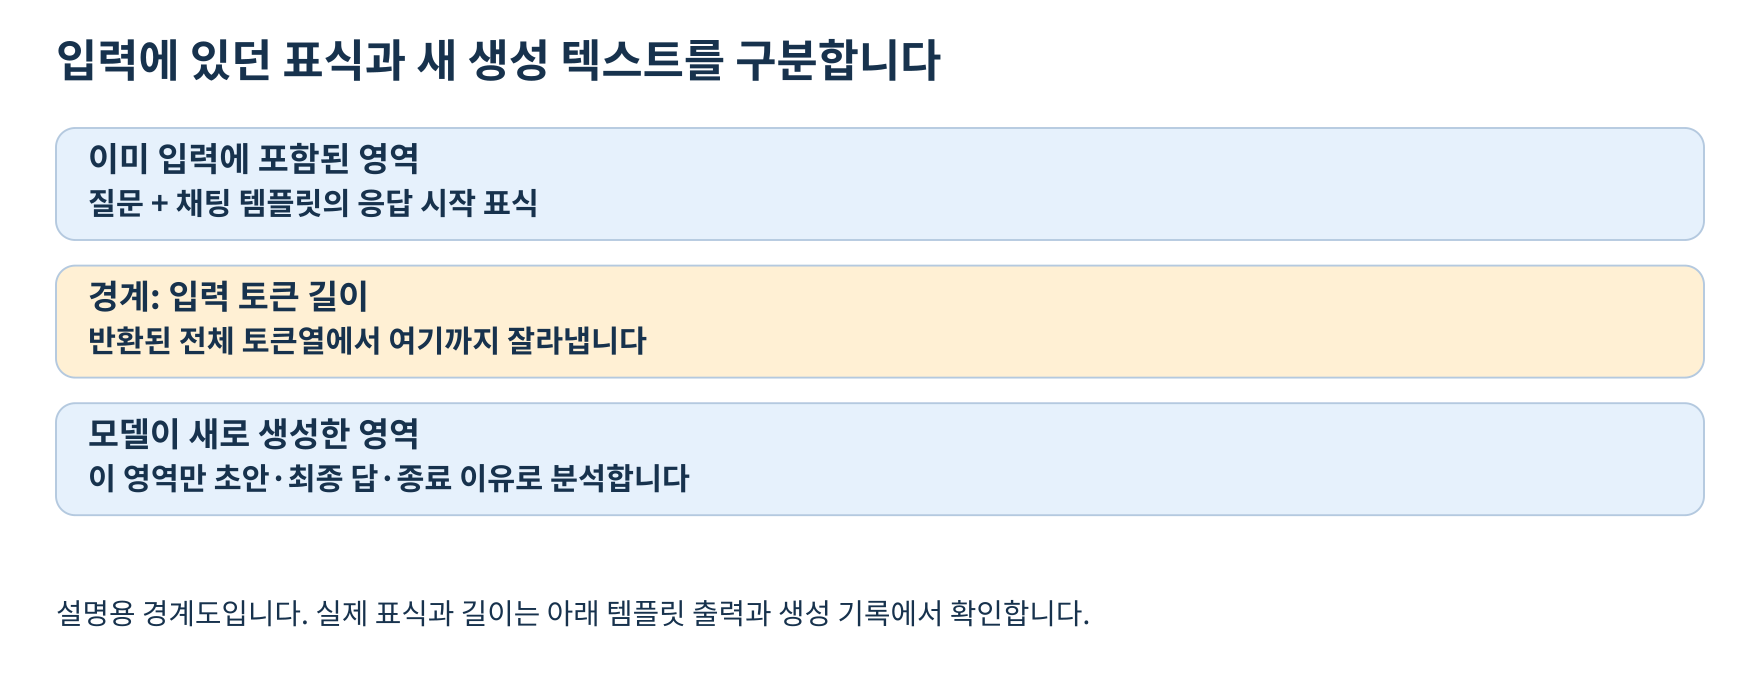

**그림 설명:** 설명용 경계도입니다. 실제 표식과 길이는 아래 템플릿 출력과 생성 기록에서 확인합니다.


### 코드 설명: 모드 차이는 실제 입력에서 확인하기

`apply_chat_template`는 질문을 역할 구분과 생성 시작 표식을 포함한 모델 전용 대화 형식으로 바꿉니다. `enable_thinking`을 바꾼 뒤 출력되는 `repr(text[-180:])`에서 입력 끝부분의 차이를 비교하세요. 같은 질문이라도 템플릿이 달라지면 입력 토큰 수도 달라질 수 있습니다. 템플릿이 이미 특수 토큰을 포함하므로 다음 토큰화에서는 `add_special_tokens=False`로 중복 추가를 피합니다.

8토큰 워밍업은 실행 초기의 준비 영향을 줄이기 위한 별도 생성이며 문제 풀이 결과에는 포함하지 않습니다. `[PASS] template 확인·짧은 warmup`은 입력 형식과 짧은 실행 준비가 확인되었다는 뜻이지, 두 모드가 같은 답을 내거나 thinking 모드가 더 좋다는 뜻은 아닙니다.


In [2]:
def make_inputs(question,thinking):
    # tokenize=False의 반환값은 문자열이며 다음 호출에서 정수 텐서로 바뀝니다.
    text=tokenizer.apply_chat_template([{"role":"user","content":question}],tokenize=False,
        add_generation_prompt=True,enable_thinking=thinking)
    # 이미 템플릿이 제어 표식을 넣었으므로 add_special_tokens=False로 중복 추가를 피합니다.
    inputs=tokenizer(text,return_tensors="pt",add_special_tokens=False).to(DEVICE)
    # 문자열은 형식 확인용, inputs는 GPU 모델 호출용입니다. 두 값을 구분해 반환합니다.
    return text,inputs
# 추상적인 모드 이름보다 실제 템플릿 문자열과 입력 토큰 수의 차이를 먼저 확인합니다.
for mode in (False,True):
    text,inputs=make_inputs(QUESTIONS[0]["text"],mode)
    print("enable_thinking:",mode,"input tokens:",inputs.input_ids.shape[1])
    print(repr(text[-180:]))
    del inputs
# 시간의 첫 초기화 영향을 줄이는 8토큰 warmup. 비교 결과에는 포함하지 않습니다.
# _에는 여기서 사용하지 않을 문자열을 받고 warm에는 모델 입력 묶음을 받습니다.
_,warm=make_inputs("Say hello briefly.",False)
# 비교 실험과 별개의 준비 생성용 seed입니다. 뒤의 4개 관찰 기록에 포함하지 않습니다.
set_seed(40)
with torch.inference_mode():
    # **warm은 입력 묶음을 이름 있는 인수로 펼칩니다. 이 생성은 비교 기록에서 제외합니다.
    _=model.generate(**warm,max_new_tokens=8,do_sample=True,temperature=.6,top_p=.95,top_k=20,min_p=0.0)
torch.cuda.synchronize(DEVICE)
del warm,_
print("[PASS] template 확인·짧은 warmup")

enable_thinking: False input tokens: 51
'cils. Mina removes 3 and adds 5. How many pencils are now in the box? End your final answer with FINAL: followed by the integer.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'
enable_thinking: True input tokens: 47
'er\nA box has 12 pencils. Mina removes 3 and adds 5. How many pencils are now in the box? End your final answer with FINAL: followed by the integer.<|im_end|>\n<|im_start|>assistant\n'


[PASS] template 확인·짧은 warmup


### 출력 설명

같은 연필 질문인데 non-thinking 입력은 51토큰, thinking 입력은 47토큰으로 출력되었습니다. 문자열 끝을 보면 non-thinking 쪽에 빈 `<think>…</think>`가 이미 들어 있습니다. 따라서 이 빈 영역을 모델이 생성한 초안으로 세면 안 됩니다. 질문 내용이 아니라 template의 제어 표식이 입력 길이를 바꾼 사례입니다.

마지막 PASS는 두 template를 만들고 별도 8토큰 워밍업 호출까지 끝났다는 뜻입니다. 이 셀에는 문제의 답을 비교한 결과가 없으며, 워밍업이 실제로 8토큰을 모두 생성했다고 별도 출력한 것도 아닙니다.


## 3. 실제 짝 비교: 가중치는 그대로, template 옵션만 변경
실행하면 실제 새 텍스트와 원시 토큰을 저장합니다. 문제마다 seed42/43을 양쪽에 동일하게 설정합니다. 두 번째 문제는 모드 실행 순서를 뒤집습니다.

**읽을 때:** `<think>` 안의 텍스트도 모델이 생성한 외부 출력입니다. 뇌 속 사고 기록이나 진실성 보증이 아닙니다. 내부 계산을 직접 보았다는 표현을 쓰지 않습니다. 확인할 것은 구분자·길이·문제의 최종 답·중단 여부입니다.

### 개념 먼저

공정한 짝 비교는 ‘같은 seed라서 같은 답이 나와야 한다’는 뜻이 아닙니다. 난수 시작점이 같아도 입력 토큰과 그에 따른 후보 분포가 달라지면 선택되는 토큰도 달라집니다. 같은 생성 상한 역시 같은 작업량을 보장하지 않습니다. 한 모드는 일찍 끝나고 다른 모드는 상한까지 이어 쓸 수 있습니다.

그래서 토큰 수, 종료 이유, 최종 영역 존재 여부, 정답 숫자 일치를 함께 봅니다. 아래 파서는 초안 속 숫자를 최종 답으로 대신 채우지 않습니다. 이는 ‘계산을 못했다’와 ‘이번 예산 안에 답을 완료하지 못했다’를 구분하기 위한 선택입니다. 실제 어느 경우인지는 저장된 원문과 판정 필드를 함께 읽어 판단합니다.


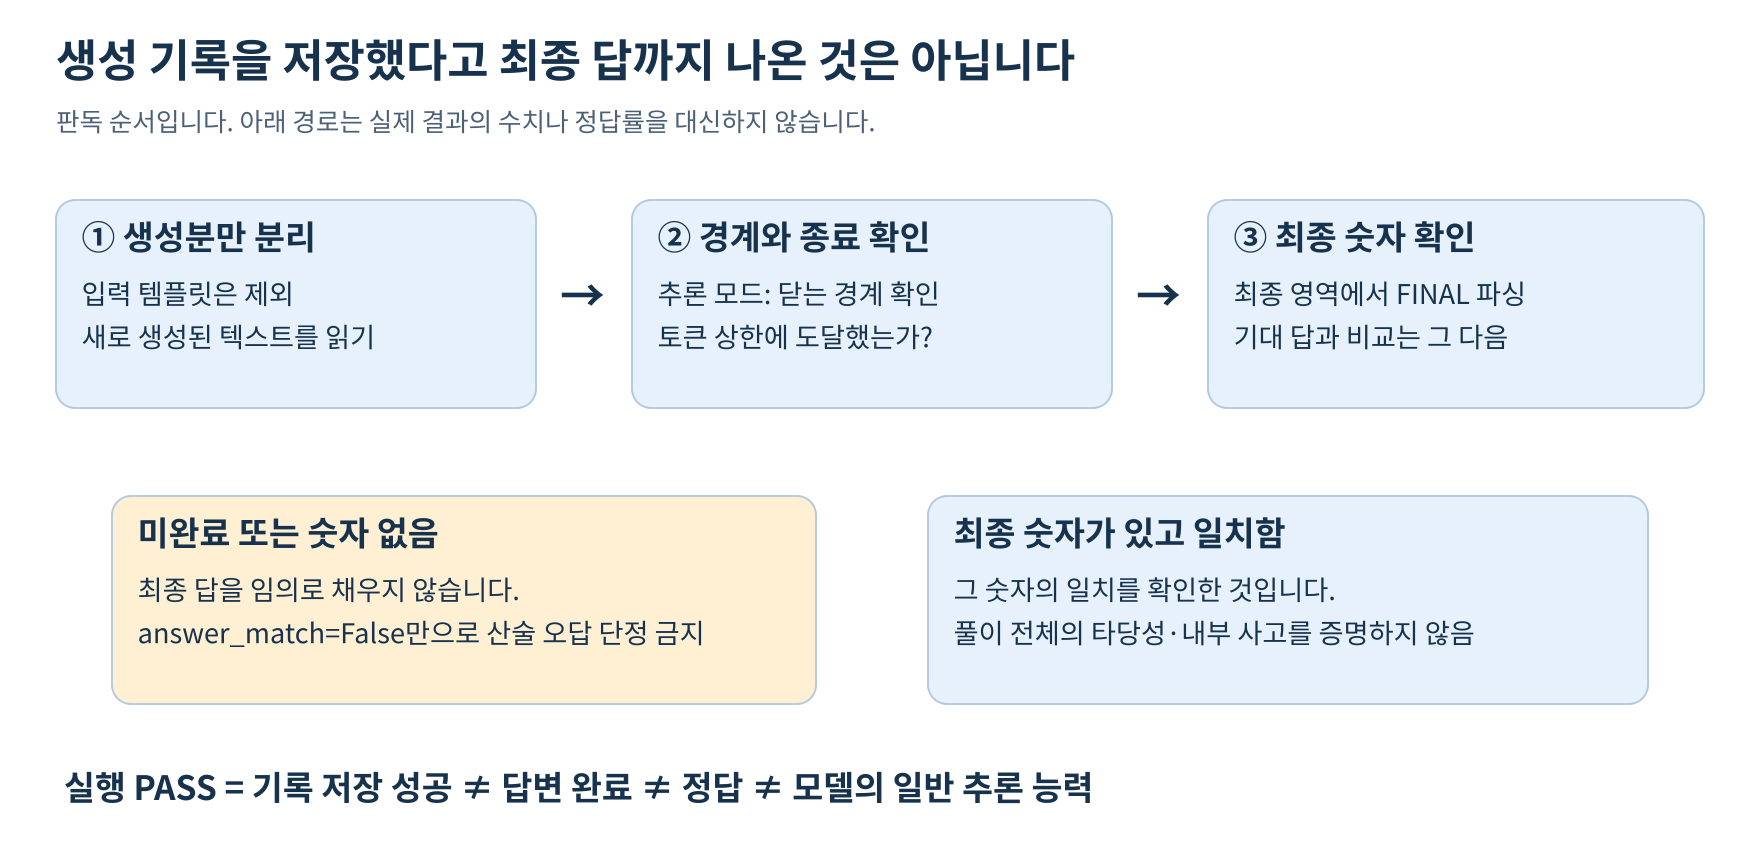

**그림 설명:** 입력과 생성분을 나눈 뒤 **토큰 상한에 닿았는지**, **지정한 형식의 최종 답을 마쳤는지**, **`FINAL:` 뒤 숫자가 맞는지**를 각각 확인합니다. 숫자가 맞더라도 토큰 상한에서 끊겼다면 완료로 세지 않습니다.


### 코드 설명: 생성 결과와 완료 여부를 분리하기

문제 2개를 모드 2개로 실행하여 4개의 관찰을 저장합니다. `output`에는 입력도 포함되므로 입력 길이 이후만 잘라 `generated`로 사용합니다. `parse_output`은 `</think>` 경계가 있을 때 초안과 최종 답을 나누고, 경계가 없으면 thinking 출력을 최종 답으로 간주하지 않습니다. `FINAL:` 뒤 숫자를 추출하는 것은 이 두 문제를 위한 간단한 채점 규칙이지 일반적인 의미 이해 채점기가 아닙니다.

`generated_tokens`, `token_cap_reached`, `complete_final`, `answer_match`를 반드시 함께 읽으세요. 토큰 한도에서 잘린 결과는 답을 마치지 못한 것이므로, 초안에 정답 숫자가 등장했다는 이유로 성공 처리하지 않습니다. seed는 재현을 돕지만 장치와 구현이 바뀌어도 완전히 같은 출력을 보장하지는 않습니다. 마지막 `[PASS]`는 4개의 실행·기록을 완료했다는 뜻이며, 두 문제만으로 추론 성능을 평가한 결론은 아닙니다.


In [3]:
def parse_output(ids,thinking):
    raw=tokenizer.decode(ids,skip_special_tokens=False)
    end_id=tokenizer.convert_tokens_to_ids("</think>")
    has_close=end_id in ids
    # 닫는 think 표식이 있을 때만 그 뒤를 최종 답 영역으로 분리합니다.
    if thinking and has_close:
        split=ids.index(end_id)
        visible_draft=tokenizer.decode(ids[:split],skip_special_tokens=True)
        final=tokenizer.decode(ids[split+1:],skip_special_tokens=True)
        draft_tokens=split
    # 닫는 표식이 없으면 아직 초안 영역으로 취급하고 최종 답을 임의로 채우지 않습니다.
    elif thinking:
        visible_draft=tokenizer.decode(ids,skip_special_tokens=True)
        final=""  # 닫는 경계가 없으면 최종 답으로 판정하지 않습니다.
        draft_tokens=len(ids)
    else:
        visible_draft=""
        final=tokenizer.decode(ids,skip_special_tokens=True)
        draft_tokens=0
    eos=model.generation_config.eos_token_id
    # 종료 ID가 정수 또는 목록일 수 있어 집합으로 통일합니다.
    eos_ids=set(eos if isinstance(eos,list) else [eos])
    stopped_eos=bool(ids and ids[-1] in eos_ids)
    # EOS로 끝났으면 길이가 상한과 같더라도 한도 강제 종료와 구분합니다.
    capped=len(ids)>=MAX_NEW_TOKENS and not stopped_eos
    # 최종 영역의 양의 정수·소수만 찾습니다. 음수·분수·서술형 채점 규칙은 아닙니다.
    # 일치 목록이 여럿이면 마지막 숫자를 선택하므로 원문도 저장해 파싱 한계를 검토합니다.
    answers=re.findall(r"FINAL:\s*([0-9]+(?:\.[0-9]+)?)",final)
    return {"raw_generated_text":raw,"visible_draft":visible_draft,"final_text":final,
            "draft_tokens":draft_tokens,"has_think_close":has_close,"eos_stop":stopped_eos,
            "token_cap_reached":capped,"stop_reason":"eos" if stopped_eos else "max_new_tokens" if capped else "other",
            "parsed_answer":answers[-1] if answers else None}

# 정답 일치뿐 아니라 토큰 한도와 최종 답 완료 여부를 별도 기록합니다.
observations=[]
for qi,question in enumerate(QUESTIONS):
    for thinking in ((False,True) if qi%2==0 else (True,False)):
        template,inputs=make_inputs(question["text"],thinking)
        # 같은 문제의 두 모드에 같은 seed를 주지만 입력이 달라 동일 문장을 보장하지 않습니다.
        set_seed(42+qi)
        torch.cuda.synchronize(DEVICE); start=time.perf_counter()
        with torch.inference_mode():
            output=model.generate(**inputs,max_new_tokens=MAX_NEW_TOKENS,do_sample=True,
                temperature=.6,top_p=.95,top_k=20,min_p=0.0,use_cache=True)
        torch.cuda.synchronize(DEVICE); elapsed=time.perf_counter()-start
        # 입력 길이만큼 잘라 새로 생성한 토큰 ID만 파싱합니다.
        generated=output[0,inputs.input_ids.shape[1]:].tolist()
        assert 0<len(generated)<=MAX_NEW_TOKENS
        parsed=parse_output(generated,thinking)
        row={"question_id":question["id"],"question":question["text"],"expected_answer":question["answer"],
             "enable_thinking":thinking,"seed":42+qi,"input_tokens":inputs.input_ids.shape[1],
             "generated_tokens":len(generated),"elapsed_generate_seconds":elapsed,
             "formatted_input":template,"generated_ids":generated,**parsed}
        # 숫자 일치 판정과 아래 답변 완료 판정을 따로 남겨 미완료와 오답을 섞지 않습니다.
        row["answer_match"]=(parsed["parsed_answer"]==question["answer"])
        # 정답 숫자 일치와 별개로 토큰 한도·최종 영역·닫는 경계를 확인합니다.
        row["complete_final"]=(not parsed["token_cap_reached"] and bool(parsed["final_text"].strip()) and
                               (not thinking or parsed["has_think_close"]))
        observations.append(row)
        print("\n===",question["id"],"thinking=",thinking,"===")
        print(parsed["raw_generated_text"])
        print({k:row[k] for k in ("generated_tokens","elapsed_generate_seconds","token_cap_reached","complete_final","answer_match")})
        (OUT/"observations.json").write_text(json.dumps({"meta":META,"observations":observations},ensure_ascii=False,indent=2),encoding="utf-8")
        del inputs,output
assert len(observations)==4
print("[PASS] 실제 4개 생성 결과 기록. 이 PASS는 정답률·추론능력 평가가 아닙니다.")


=== pencils thinking= False ===
Mina starts with 12 pencils in the box.  
She removes 3 pencils and adds 5 pencils.  

So, the total number of pencils is:

$$
12 - 3 + 5 = 14
$$

**Final answer:** FINAL: 14<|im_end|>
{'generated_tokens': 61, 'elapsed_generate_seconds': 1.8751932999985002, 'token_cap_reached': False, 'complete_final': True, 'answer_match': True}



=== pencils thinking= True ===
<think>
Okay, let's see. There's a box with 12 pencils. Mina removes 3 and adds 5. I need to find out how many pencils are now in the box. Hmm, let me think step by step.

First, the initial number of pencils is 12. Then, she removes 3. So, if I subtract 3 from 12, that should give me the number of pencils after she removes them. Let me do that calculation. 12 minus 3 is... 9. So, after removing 3, there are 9 pencils left.

Then, she adds 5. So, instead of subtracting 3, I need to add 5 to the current number of pencils. So, 9 plus 5. Let me add those. 9 plus 5 is 14. So, now there are 14 pencils in the box.

Wait, let me check again to make sure I didn't make a mistake. Starting with 12, subtract 3: 12 - 3 = 9. Then add 5: 9 + 5 = 14. Yeah, that seems right. So, the final answer should be 14.

But just to be thorough, let me visualize it. Imagine the box starts with 12 pencils. If I take out 3, I have 9 left. Then, adding 5, so adding 5 to 9. 9 + 5 is 1


=== decimal thinking= True ===
<think>
Okay, let's see. The question is asking which decimal number is larger between 9.11 and 9.9. Hmm, I need to compare these two numbers. Let me think about how to do this.

First, both numbers are in the same place value system. 9.11 and 9.9. They both have a 9 before the decimal point. So, maybe I can subtract them to see which one is bigger. Let me try that.

If I subtract 9.11 from 9.9, that would be 9.9 minus 9.11. Let me calculate that. 9.9 minus 9 is 0.9, and then minus 0.11 would be 0.9 minus 0.11, which is 0.79. So, 9.9 minus 9.11 equals 0.79. That means 9.9 is larger than 9.11 by 0.79. 

Alternatively, since both numbers are 9.11 and 9.9, I can compare the decimal digits directly. Both numbers start with the same digits, so the first digit after the decimal is 1 and 9. Since 9 is greater than 1, that means 9.9 is larger. 

Wait, let me double-check. If I have 9.11, the first decimal place is 1, then another 1. In 9.9, the first decimal pla


=== decimal thinking= False ===
The decimal number **9.9** is larger than **9.11**.

**FINAL: 9.9**.<|im_end|>
{'generated_tokens': 28, 'elapsed_generate_seconds': 0.8402602999994997, 'token_cap_reached': False, 'complete_final': True, 'answer_match': True}
[PASS] 실제 4개 생성 결과 기록. 이 PASS는 정답률·추론능력 평가가 아닙니다.


### 출력 설명

저장된 네 생성 결과에서 non-thinking은 연필 문제를 61토큰으로 마치고 최종 숫자 14를 냈으며, 소수 비교는 28토큰으로 마치고 9.9를 냈습니다. 두 기록 모두 최종 답 완료와 숫자 일치가 참입니다. 반면 thinking 두 기록은 각각 384토큰 상한에 도달해 완료가 거짓이고 최종 숫자도 파싱되지 않았습니다.

연필 thinking 출력은 닫는 think 경계 뒤로 넘어갔지만 최종 풀이가 중간에서 끊겼습니다. 소수 thinking 출력은 정답 방향의 숫자를 초안에 언급해도 닫는 경계와 완성된 최종 답까지 도달하지 못했습니다. 따라서 `answer_match=False`를 “완성된 최종 답으로 틀린 숫자를 냈다”와 동일하게 해석하지 않습니다. 네 기록 PASS는 관찰·저장 성공이지 thinking의 일반 성능 열세를 입증하지 않습니다. 실행 시간은 각 생성의 실제 길이와 모드가 달라 같은 작업량의 속도 비교도 아닙니다.


## 4. 결과표와 한계
`answer_match`는 지정된 FINAL 숫자만 비교한 좁은 확인입니다. 모든 주장이나 풀이가 옳다는 뜻이 아닙니다. `complete_final=False`이면 중단/형식 문제를 먼저 표시합니다. 최종 답이 없으면 정답률 비교에서 완성된 오답과 섞지 마세요.

어느 쪽이 길거나 느리거나 틀리더라도 그대로 기록합니다. 생성 텍스트의 길이가 지능 척도는 아니며, 이 두 문제와 한 번의 표본은 모드 성능의 통계적 평가가 아닙니다.

### 코드 설명: 긴 출력과 좋은 답은 다릅니다

이 결과가 보여 주는 것은 제한된 생성 예산 안에서의 실제 동작입니다. thinking 출력은 풀이를 전개할 공간을 주지만 시간과 토큰을 더 소비할 수 있고, 항상 정확도 향상으로 이어지는 것은 아닙니다. 반대로 이 두 결과만으로 thinking 방식 전체가 열등하다고 결론 내리지 않습니다. `observations.json`에 입력·출력·중단 이유·실행 조건을 보관한 뒤 모델을 정리합니다.


In [4]:
# 답의 숫자만 보지 말고 complete_final과 생성 토큰 수를 함께 읽습니다.
# 같은 question_id의 두 모드를 짝지어 길이·완료 여부·답을 비교합니다.
for r in observations:
    print(r["question_id"],"thinking=",r["enable_thinking"],"tokens=",r["generated_tokens"],
          "visible draft tokens=",r["draft_tokens"],"complete final=",r["complete_final"],
          "parsed=",r["parsed_answer"],"expected=",r["expected_answer"])
# 화면 요약에 생략된 원시 생성문과 실행 조건은 이 폴더의 JSON에서 다시 확인합니다.
print("증거 폴더:",OUT.resolve())
# 모델 참조를 지운 뒤 사용하지 않는 GPU 캐시를 반환하며 결과 파일은 지우지 않습니다.
del model,tokenizer
# 참조 제거 후 회수 가능한 객체와 미사용 GPU 캐시를 정리합니다. 살아 있는 텐서까지 강제로 삭제하지 않습니다.
gc.collect();torch.cuda.empty_cache()
print("[PASS] 모델 메모리 정리")

pencils thinking= False tokens= 61 visible draft tokens= 0 complete final= True parsed= 14 expected= 14
pencils thinking= True tokens= 384 visible draft tokens= 346 complete final= False parsed= None expected= 14
decimal thinking= True tokens= 384 visible draft tokens= 384 complete final= False parsed= None expected= 9.9
decimal thinking= False tokens= 28 visible draft tokens= 0 complete final= True parsed= 9.9 expected= 9.9
증거 폴더: %USERPROFILE%\AI-Engineering\lesson10-qa-20261117\results\lesson10\20261117-221059-975232
[PASS] 모델 메모리 정리


### 출력 설명

요약표에서 non-thinking 두 줄은 `complete final=True`이며 파싱한 값이 각각 14와 9.9입니다. thinking 두 줄은 모두 `parsed=None`입니다. 이는 숫자 0이나 다른 오답을 냈다는 뜻이 아니라 규칙에 맞는 최종 숫자를 얻지 못했다는 뜻입니다.

연필 thinking의 보이는 초안은 346토큰으로 전체 384토큰보다 짧아 경계 이후에도 일부 생성했음을 보여 줍니다. 소수 thinking은 초안 길이가 전체 길이와 같은 384토큰으로 기록됐습니다. 이 길이는 생성 텍스트 분할 결과이지 내부 사고량이 아닙니다. 마지막 저장 폴더와 메모리 정리 PASS는 기록 위치·정리 실행을 확인할 뿐, 최종 답을 새로 생성하거나 품질을 개선한 결과는 아닙니다.


## 정리와 자기 점검
- 두 모드의 입력 template가 다르다는 것을 어디서 확인했나요?

   **핵심 답과 이유:** template 비교 출력에서 입력은 non-thinking 51토큰, thinking 47토큰입니다. non-thinking 문자열 끝에는 빈 think 영역이 이미 포함돼 있습니다. 같은 질문이라도 제어 표식이 달라진 것이며 이 입력 영역을 생성된 초안으로 세지 않습니다.

- `</think>`가 없고 길이 제한에 걸린 출력을 왜 최종 답으로 읽으면 안 될까요?

   **핵심 답과 이유:** 닫는 경계가 없으면 생성물이 아직 초안 영역에 있고, 상한 도달은 답변 완료의 증거가 아닙니다. 저장된 소수 thinking 사례는 384토큰에서 멈춰 최종 숫자가 `None`입니다. 초안에 9.9가 등장해도 완료된 최종 답으로 대신 채우지 않습니다.

- 실제 생성된 설명을 보았다는 것과 모델 내부 계산을 이해했다는 것은 어떻게 다르나요?

   **핵심 답과 이유:** 보이는 설명은 모델이 생성한 텍스트입니다. 내부의 모든 활성값·계산 경로나 인과 관계를 그대로 보여 주는 기록은 아닙니다. 설명이 길거나 그럴듯해도 실제 계산을 완전히 복원했다고 말할 수 없습니다.

- 이 실험으로 ‘아키텍처가 reasoning을 만들었다’고 말할 수 없는 이유는 무엇인가요?

   **핵심 답과 이유:** 구조와 가중치는 같은 Qwen3-0.6B로 유지하고 template 옵션만 바꿨습니다. 아키텍처 유무를 바꾼 대조 실험이 아니며 문제도 두 개뿐이어서 일반적인 reasoning 발생 원인을 규명하지 못합니다.

- 더 신뢰할 비교를 하려면 문제 수·seed·예산·채점·하드웨어 조건을 어떻게 늘리거나 통제해야 할까요?

   **핵심 답과 이유:** 문제 유형과 개수를 늘리고 여러 seed를 반복합니다. 생성 예산·정밀도·장치·구현·샘플링을 통제하고, 완료 여부와 최종 정답 및 풀이 타당성을 별도 채점합니다. 시간 비교도 토큰 수·작업량 차이와 함께 보고하며 같은 seed만으로 다른 장치의 동일 출력을 보장하지 않습니다.


다음 교시에서는 텍스트 대신 이미지 패치를 Transformer 입력으로 만듭니다. 여기서 배운 실행 성공·출력 완료·정답의 구분은 이미지 분류와 설명에도 그대로 적용합니다.


## 참고 자료

[고정 Qwen3-0.6B 공식 모델 카드](https://huggingface.co/Qwen/Qwen3-0.6B/blob/c1899de289a04d12100db370d81485cdf75e47ca/README.md), [Qwen3 기술 보고서](https://arxiv.org/abs/2505.09388). 공식 설명과 이 Notebook의 실제 관찰 결과를 구분하세요.
